# Week 3 Assignment: Linear Regression & Logistic Regression
**AI and Machine Learning Track**
## Instructions
1. Work through the notebook **from top to bottom**. Run every cell in order.
2. Replace each `# YOUR CODE HERE` cell with your own code. Read the **hint** under it if you get stuck.
3. For the **written answers**, double-click the answer box and type 2 to 4 sentences **in your own words**.
4. Before submitting, click **Kernel > Restart & Run All** (or *Runtime > Restart and run all* in Colab) to confirm your whole notebook runs without errors.
5. Save the notebook with the name `Week3_Assignment_YourName.ipynb` and submit it.


In [3]:
# Run this cell first. You may add more imports if you need them.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score)

---
# PART A: Linear Regression 
## Scenario
A shop in Abuja sells **used laptops**. The owner wants a model that suggests a fair selling price from the laptop's **RAM**, **storage** and **age**. You have records of **250 past sales**.

| Column | Meaning |
|---|---|
| `ram_gb` | RAM in gigabytes |
| `storage_gb` | Storage in gigabytes |
| `age_years` | Age of the laptop in years |
| `price_thousand` | Selling price in thousands of naira (**the label we want to predict**) |

In [23]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(2024)
n = 250

laptops = pd.DataFrame({
    "ram_gb":     rng.choice([4, 8, 16, 32], n, p=[0.2, 0.4, 0.3, 0.1]),
    "storage_gb": rng.choice([128, 256, 512, 1024], n, p=[0.2, 0.35, 0.3, 0.15]),
    "age_years":  rng.integers(0, 7, n),
})
laptops["price_thousand"] = (
    150 + 9 * laptops["ram_gb"] + 0.12 * laptops["storage_gb"]
    - 18 * laptops["age_years"] + rng.normal(0, 25, n)
).round(1)

laptops.head()

,ram_gb,storage_gb,age_years,price_thousand
0,16,1024,6,331.0
1,8,128,2,201.4
2,8,128,1,194.8
3,16,256,6,253.0
4,32,512,1,515.5


### A1. Explore the data

Using code, show: (a) the number of rows and columns, (b) the summary statistics, (c) whether there are missing values, and (d) the **correlation of every column with `price_thousand`**.

Then draw **one scatter plot** of `age_years` against `price_thousand` with axis labels and a title.

In [24]:
""" code showing:
(a) the number of rows and columns
(b) the summary statistics
"""
print("(a) the number of rows and columns:", laptops.shape)
print()
print("(b) the summary statistics:")
laptops.describe(include="all").T


# Hint: `.shape`, `.describe()`, `.isnull().sum()`, `.corr()`, `plt.scatter(...)`.

(a) the number of rows and columns: (250, 4)

(b) the summary statistics:


,count,mean,std,min,25%,50%,75%,max
ram_gb,250.0,11.2960,7.739767,4.0,8.00,8.0,16.0,32.0
storage_gb,250.0,420.8640,294.182451,128.0,256.00,256.0,512.0,1024.0
age_years,250.0,3.2200,1.986804,0.0,1.00,3.0,5.0,6.0
price_thousand,250.0,243.9424,90.765017,54.8,177.65,231.1,284.9,515.5


In [25]:
""" code showing:
(c) the number of missing values in each column
"""
print("(c) the number of missing values in each column:")
laptops.isnull().sum()

(c) the number of missing values in each column:


ram_gb            0
storage_gb        0
age_years         0
price_thousand    0
dtype: int64

In [26]:
""" code showing:
(d1) the correlation of every column with price_thousand
"""
print("(d1) the correlation of every column with price_thousand:")
laptops.corr()['price_thousand'] 

(d1) the correlation of every column with price_thousand:


ram_gb            0.808453
storage_gb        0.404458
age_years        -0.355518
price_thousand    1.000000
Name: price_thousand, dtype: float64

In [27]:
""" code showing:
(d2) the correlation of every column with price_thousand (sorted in descending order and rounded to 2 decimal places)
"""
print("(d2) the correlation of every column with price_thousand (sorted in descending order and rounded to 2 decimal places):")
laptops.corr()['price_thousand'].sort_values(ascending=False).round(2)

(d2) the correlation of every column with price_thousand (sorted in descending order and rounded to 2 decimal places):


price_thousand    1.00
ram_gb            0.81
storage_gb        0.40
age_years        -0.36
Name: price_thousand, dtype: float64

(e) one scatter plot of age_years against price_thousand with axis labels and a title:


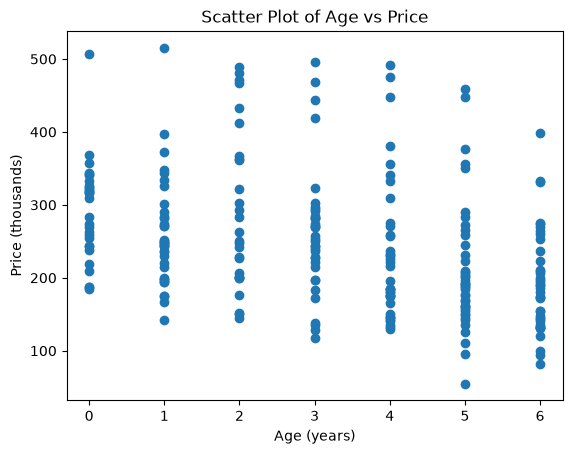

In [28]:
""" code showing:
(e) the drawing of "one scatter plot" of `age_years` against `price_thousand` with axis labels and a title.
"""
# matplotlib.pyplot as plt already imported in previous cells.

print("(e) one scatter plot of age_years against price_thousand with axis labels and a title:")
plt.scatter(laptops['age_years'], laptops['price_thousand'])
plt.xlabel('Age (years)')
plt.ylabel('Price (thousands)')
plt.title('Scatter Plot of Age vs Price')
plt.show()


### A2. Prepare the data  
Create `X` (the three feature columns) and `y` (the label). Split into **80% training and 20% testing** using `random_state=42`. Print the number of rows in each set.

In [29]:
# creating the features (X) and the label or target variable (y)
X = laptops[["ram_gb", "storage_gb", "age_years"]]
y = laptops["price_thousand"]

print("Printing the shape of the features and target variable...")
print("X shape:", X.shape)
print("y shape:", y.shape)

print()

# Splitting the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Printing the number of rows in the training and testing sets...")
print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

# Hint: `laptops[[...]]`, `train_test_split(X, y, test_size=..., random_state=...)`.

Printing the shape of the features and target variable...
X shape: (250, 3)
y shape: (250,)

Printing the number of rows in the training and testing sets...
Training rows: 200
Testing rows:  50


### A3. Train the model 

Train a **Linear Regression** model on the training data. Print the **intercept** and show the **coefficients in a table** (one row per feature).

In [30]:
# Fitting the linear regression model
laptop_model = LinearRegression()
laptop_model.fit(X_train, y_train)

# Printing the intercept of the fitted model and rounding it to 2 decimal places
print("Intercept:  ", round(laptop_model.intercept_, 2))

print()

# Showing the coefficients of the fitted model in a table with two columns: "Feature" and "Coefficient", rounded to 3 decimal places
print("The Coefficients in a table:")
coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": laptop_model.coef_.round(3)})
coef_table

# Hint: `LinearRegression()`, `.fit()`, `.intercept_`, `.coef_`, `pd.DataFrame(...)`.

Intercept:   145.23

The Coefficients in a table:


,Feature,Coefficient
0,ram_gb,8.825
1,storage_gb,0.124
2,age_years,-16.160


### A4. Interpret the coefficients 

In your own words, explain what the coefficient of `age_years` means for the shop owner. Is it positive or negative, and does that make sense? Then say what the coefficient of `ram_gb` tells you.

**Your answer:**

### My Interpretation of the coefficients
For every 1-unit increase, while holding other features constant:
- The **negative** coefficient of the **age_years** means for the shop owner a **decrease** in **price_thousand** of his laptop.
- While the **positive** coefficient of the **ram_gb** means for the shop owner an **upshoot** in **price_thousand** of his laptop.


### A5. Make a prediction 

Use your model to predict the price of a laptop with **16 GB RAM, 512 GB storage and 2 years old**. Print the answer in a sentence, for example: *"The predicted price is about N___ thousand."*

In [35]:
# Predict the price of a the laptop with 16GB RAM, 512GB storage, and 2 years old using the fitted model. Print the predicted price rounded to 1 decimal place.
new_laptop = pd.DataFrame({
    "ram_gb": [16], "storage_gb": [512], "age_years": [2]
})
price = laptop_model.predict(new_laptop)
print(f"The predicted price is: about N{price[0]:.1f} thousand")

# Hint: Put the new laptop in a DataFrame with the **same column names** as `X`, then use `model.predict(...)`.

The predicted price is: about N317.4 thousand


### A6. Evaluate the model 

Predict on the **test set** and calculate **MAE, RMSE and R²**. Print each with a short label.

Then draw an **Actual vs Predicted** scatter plot with a red dashed line showing perfect prediction.

In [36]:
# Evaluating the model's performance on the test set
reg_model = laptop_model.fit(X_train, y_train)
y_pred = reg_model.predict(X_test)

# Calculating the evaluation metrics: MAE, MSE, RMSE, and R²
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

# Printing the evaluation metrics with appropriate formatting
print(f"MAE : {mae:.2f}  -> on average, predictions are off by about N{mae:.1f} Thousand")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.3f}  -> the model explains about {r2*100:.0f}% of the variation in prices")

# Hint: `model.predict(X_test)`, `mean_absolute_error`, `mean_squared_error` (then `np.sqrt`), `r2_score`.

MAE : 21.28  -> on average, predictions are off by about N21.3 Thousand
MSE : 788.33
RMSE: 28.08
R²  : 0.929  -> the model explains about 93% of the variation in prices


### A7. Is the model good?  

Use your MAE and R² values to explain, in plain language, how good the model is. Would you trust it to price laptops in the shop? Give one idea for improving it.

**Your answer:**

*(double-click here and type your answer)*

---
# PART B: Logistic Regression 
## Scenario
A microfinance company in Nigeria gives small loans. For each past loan they know whether the customer **repaid (1)** or **did not repay (0)**. They want a model to help decide whether to approve **new** applicants. You have records of **400 past loans**.

| Column | Meaning |
|---|---|
| `monthly_income_k` | Customer's monthly income (N thousand) |
| `loan_amount_k` | Loan amount requested (N thousand) |
| `years_employed` | Years in current job or business |
| `previous_defaults` | Number of earlier loans not repaid |
| `repaid` | 1 = repaid, 0 = did not repay (**the label**) |

In [37]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(99)
m = 400

loans = pd.DataFrame({
    "monthly_income_k":  rng.normal(120, 40, m).clip(30).round(0),
    "loan_amount_k":     rng.uniform(20, 500, m).round(0),
    "years_employed":    rng.uniform(0, 15, m).round(1),
    "previous_defaults": np.minimum(rng.poisson(0.6, m), 3),
})
z = (-1.0 + 0.025 * loans["monthly_income_k"] - 0.008 * loans["loan_amount_k"]
     + 0.12 * loans["years_employed"] - 1.2 * loans["previous_defaults"])
prob = 1 / (1 + np.exp(-z))
loans["repaid"] = (rng.random(m) < prob).astype(int)

loans.head()

,monthly_income_k,loan_amount_k,years_employed,previous_defaults,repaid
0,123.0,407.0,14.0,2,1
1,101.0,407.0,2.1,1,0
2,122.0,339.0,12.9,0,1
3,147.0,408.0,8.6,0,1
4,50.0,202.0,2.3,1,0


### B1. Explore the data

Show (a) how many loans were repaid and not repaid (counts **and** percentages), and (b) the **average of each feature for repaid vs not repaid** loans.

Then, in one sentence in a comment or print statement, say which feature seems to differ the most between the two groups.

In [ ]:


# Hint: `.value_counts()`, `.value_counts(normalize=True)`, `.groupby('repaid').mean()`.

### B2. Prepare and train 

Create `X` (all columns except `repaid`) and `y`. Split into 80% training and 20% testing with `random_state=42` and **`stratify=y`**.

Build a **pipeline** that scales the features with `StandardScaler` and then trains a `LogisticRegression`. Fit it on the training data.

In [ ]:
# YOUR CODE HERE
# Hint: `make_pipeline(StandardScaler(), LogisticRegression())`, then `.fit(X_train, y_train)`.

### B3. Accuracy and a new applicant

(a) Print the model's **accuracy on the test set**.

(b) A new applicant earns **N90 thousand** a month, wants a loan of **N250 thousand**, has been employed for **3 years** and has **1 previous default**. Print the **predicted class** and the **probability of repaying**.

In [ ]:
# YOUR CODE HERE
# Hint: `accuracy_score`, `log_model.predict(...)`, `log_model.predict_proba(...)`. The probability of class 1 is the **second** number.

### B4. Evaluate with a confusion matrix 

Show the **confusion matrix** (as a plot or printed table) and a **classification report** for the test set.

In [ ]:
# YOUR CODE HERE
# Hint: `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`.

### B5. Which mistake is worse? 

In this loan problem, **1 = repaid** is the "positive" class.

Explain in your own words what a **false positive** and a **false negative** mean here. Which one costs the company more, and which metric (precision or recall for the "Repaid" class) would you watch most closely?

**Your answer:**

*(double-click here and type your answer)*

### B6. Compare with a Decision Tree 

Train a `DecisionTreeClassifier(max_depth=3, random_state=42)` on the same training data and print its **test accuracy**. Then print the two accuracies side by side. Which model did better?

In [ ]:
# YOUR CODE HERE
# Hint: Trees do not need scaling. Use `.fit()`, `.predict()` and `accuracy_score`.

### B7. Challenge: change the decision threshold 

By default the model approves anyone with a repayment probability **above 0.5**. The company wants to be **stricter** and only approve applicants with a probability **above 0.7**.

Use `predict_proba` to apply this new threshold on the test set, then print the **precision and recall** for the "Repaid" class **before and after**. What changed?

In [ ]:
# YOUR CODE HERE
# Hint: `probs = log_model.predict_proba(X_test)[:, 1]`, then `new_pred = (probs > 0.7).astype(int)`.

---
# PART C: Reflection
Answer in your own words, in 2 to 4 sentences each.

### C1. Linear vs Logistic

What is the main difference between Linear Regression and Logistic Regression? Give one real-life example for each.

**Your answer:**

*(double-click here and type your answer)*

### C2. Why split the data? 

Why do we split our data into a training set and a test set? What could go wrong if we tested the model on the same data it learned from?

**Your answer:**

*(double-click here and type your answer)*

### C3. Why scale for logistic regression? 

In Part B we used `StandardScaler` before logistic regression. Why is scaling useful when features such as `monthly_income_k` (about 120) and `previous_defaults` (0 to 3) have very different ranges?

**Your answer:**

*(double-click here and type your answer)*

---
## Before you submit: checklist
- [ ] I ran **Restart & Run All** and there are no errors
- [ ] Every `# YOUR CODE HERE` cell has my own code
- [ ] I answered all the written questions in my own words
- [ ] My plots have titles and axis labels
- [ ] I saved the file as `Week3_Assignment_YourName.ipynb`

**Good luck!**